# KOWAS-EPI 모델 학습·평가 노트북 (The사랑해팀, r2_plant_v7_safe)

이 노트북은 제출 모델(`model.py`)의 **실행 환경 확인 → 평가 창 1개 실행 → 제출 결과 검증 → 성능·기여도 확인**을 순서대로 보여 줍니다.

- 이 모델에는 **저장된 학습 가중치가 없습니다.** 평가기가 원점 주차마다 그 시점까지의 공개 자료로 `fit`(학습)과 `predict`(예측)를 다시 실행합니다(대회 규정 §9-1).
- 대회 배포 자료(KOWAS-EPI v2.5)는 **패키지에 포함하지 않았습니다.** 4번 셀의 `KOWAS_DIR`에 배포 폴더 경로를 지정하면 실행됩니다. 지정하지 않으면 해당 셀은 건너뜁니다.
- 노트북 출력에는 점수와 성능 요약만 있고, KOWAS 관측값은 들어 있지 않습니다.

In [1]:
# 1. 실행 환경
import sys, platform, os
import numpy, sklearn, scipy
print("OS        :", platform.platform())
print("Python    :", sys.version.split()[0])
print("numpy     :", numpy.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy     :", scipy.__version__)
print("CPU 코어  :", os.cpu_count(), "(모델은 1스레드로 실행)")
print("GPU/CUDA  : 사용하지 않음")

OS        : Linux-6.18.44-fc-v242-x86_64-with-glibc2.39
Python    : 3.13.16
numpy     : 2.5.3
scikit-learn: 1.9.1
scipy     : 1.18.1
CPU 코어  : 2 (모델은 1스레드로 실행)
GPU/CUDA  : 사용하지 않음


## 2. 설정

`KOWAS_DIR`은 `evaluation.py`가 있는 KOWAS-EPI 배포 폴더입니다. 환경변수 `KOWAS_DIR`로 줄 수도 있습니다. `FOLD`는 시연용 평가 창 1개(약 1~3분)이고, `FOLD = None`이면 10개 창 전체(약 20~35분)를 실행합니다.

In [2]:
import os, subprocess, pathlib, re
HERE = pathlib.Path.cwd()
PKG = HERE.parent if HERE.name == "notebooks" else HERE      # KOWAS-EPI_model 폴더
KOWAS_DIR = os.environ.get("KOWAS_DIR", "")                  # 예: ~/KOWAS-EPI
FOLD = "2024-Q2"                                              # None 이면 전체 10개 창
RUN_LIVE = bool(KOWAS_DIR) and (pathlib.Path(KOWAS_DIR) / "evaluation.py").exists()
print("모델 폴더 :", PKG.name)
print("실행 가능 :", RUN_LIVE, "(KOWAS_DIR 지정 필요)" if not RUN_LIVE else "")

모델 폴더 : KOWAS-EPI_model
실행 가능 : True 


## 3. 모델 실행 (평가기가 원점마다 학습 → 예측)

평가기는 평가 창마다 새 프로세스를 띄워 `model.py`의 `Model.fit`과 `Model.predict`를 호출합니다. 원점 이후 자료는 모델에 전달되지 않습니다.

In [3]:
out_pred, out_json = PKG / "results" / "predictions.csv", PKG / "results" / "score.json"
if RUN_LIVE:
    out_pred.parent.mkdir(exist_ok=True)
    cmd = [sys.executable, "evaluation.py", "backtest", "--model", str(PKG / "model.py"),
           "--out", str(out_pred), "--json", str(out_json)]
    if FOLD: cmd += ["--folds", FOLD]
    env = dict(os.environ, OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1", PYTHONUTF8="1")
    r = subprocess.run(cmd, cwd=KOWAS_DIR, env=env, capture_output=True, text=True)
    for line in (r.stdout + r.stderr).splitlines():
        print(line.replace(str(PKG), "<KOWAS-EPI_model>"))           # 경로는 가려서 출력
    print("종료 코드:", r.returncode)
else:
    print("KOWAS_DIR 미지정: 실행을 건너뜁니다. 5번부터는 제출본 결과 파일로 확인할 수 있습니다.")

2024-Q2  회귀 n=221  sMAPE  52.17% (기준선  67.60%)  분류 n=221  Macro-F1 0.6896  점수 0.4127  42.9초
최종 정량점수 (평가 창 1개 평균) = 0.4127
예측 221행 → <KOWAS-EPI_model>/results/predictions.csv
종료 코드: 0


## 4. 제출본과 같은 결과인지 확인

방금 만든 결과가 제출한 `predictions.csv`의 같은 행과 일치하는지 봅니다(농도 상대오차, 경보 차이).

In [4]:
if RUN_LIVE and out_pred.exists():
    r = subprocess.run([sys.executable, str(PKG / "scripts" / "check_predictions.py"), str(out_pred),
                        "--keys", str(pathlib.Path(KOWAS_DIR) / "eval_keys.csv"),
                        "--compare", str(PKG / "predictions.csv")] + (["--folds"] if FOLD else []),
                       capture_output=True, text=True)
    print(r.stdout.replace(str(PKG), "<KOWAS-EPI_model>"), r.stderr)
else:
    print("건너뜀")

<KOWAS-EPI_model>/results/predictions.csv: 221행
평가 키 2159개 대비 확인 완료
비교 <KOWAS-EPI_model>/predictions.csv: 공통 221행, 농도 최대 상대오차 0.00e+00, 경보 차이 0행
형식 검증 통과
 


## 5. 제출본의 평가 창별 성능 (공식 10개 창)

In [5]:
import json
sc = json.load(open(PKG / "score.json", encoding="utf-8"))["folds"]
print(f"{'창':<8}{'점수':>8}{'sMAPE%':>9}{'기준선%':>9}{'Macro-F1':>10}{'상태':>6}")
for f in sc:
    print(f"{f['fold_id']:<8}{f['score']:>8.4f}{f['smape']:>9.2f}{f['smape_baseline']:>9.2f}{f['macro_f1']:>10.4f}{f['status']:>6}")
print("평균 점수:", round(sum(f['score'] for f in sc) / len(sc), 4), "(공식 기준 모델 0.2212)")

창             점수   sMAPE%     기준선%  Macro-F1    상태
2024-Q2   0.4127    52.17    67.60    0.6896    ok
2024-Q3   0.4975    63.52    90.86    0.7924    ok
2024-Q4   0.4806    52.40    72.76    0.7817    ok
2025-Q1   0.2717    57.67    60.24    0.6154    ok
2025-Q2   0.3347    48.80    56.72    0.6272    ok
2025-Q3   0.3318    52.02    58.35    0.6670    ok
2025-Q4   0.3963    48.04    69.00    0.5349    ok
2026-Q1   0.2416    54.75    56.42    0.5597    ok
2026-Q2   0.3922    47.07    57.62    0.7057    ok
2026-Q3   0.4303    49.66    71.31    0.6204    ok
평균 점수: 0.3789 (공식 기준 모델 0.2212)


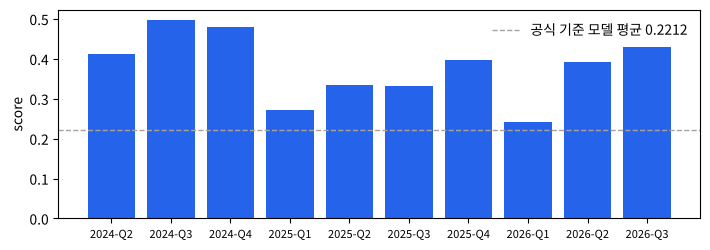

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.bar([f["fold_id"] for f in sc], [f["score"] for f in sc], color="#2563eb")
ax.axhline(0.2212, color="#a8a29e", ls="--", lw=1, label="공식 기준 모델 평균 0.2212")
ax.set_ylabel("score"); ax.legend(frameon=False); plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

## 6. 모듈별 기여도와 강수 비교 실험 (이미 실행해 둔 결과)

아래 숫자는 같은 코드에서 모듈을 하나씩 뺀 뒤 공식 10개 창을 다시 돌린 결과입니다(README 7절, `REVIEW.md`). 이 노트북에서 다시 계산하지 않습니다.

In [7]:
abl = {"전체 모델": 0.3789, "− LSTM·GRU": 0.3681, "− 처리장 구성 보정": 0.3737, "− 장기 학습기": 0.3758,
       "− 경보 임계값 학습": 0.3767, "− 온라인 오차 보정": 0.3780, "− 상태 공간 결합": 0.3784, "코어만": 0.3675}
for k, v in abl.items(): print(f"{k:<16}{v:.4f}  ({v-0.3789:+.4f})")
print()
rain = {"R0 강수 입력 전부 제외": 0.3597, "ASOS 강수 특징만": 0.3612, "패널 시·도 강수만 (R1)": 0.3782, "둘 다 (제출 모델)": 0.3789}
for k, v in rain.items(): print(f"{k:<22}{v:.4f}")
print("\n강수는 예측 기여만 확인했고, 희석 신호를 복원했다는 증거는 아닙니다(README 4.4, 7.4, 11절).")

전체 모델           0.3789  (+0.0000)
− LSTM·GRU      0.3681  (-0.0108)
− 처리장 구성 보정     0.3737  (-0.0052)
− 장기 학습기        0.3758  (-0.0031)
− 경보 임계값 학습     0.3767  (-0.0022)
− 온라인 오차 보정     0.3780  (-0.0009)
− 상태 공간 결합      0.3784  (-0.0005)
코어만             0.3675  (-0.0114)

R0 강수 입력 전부 제외        0.3597
ASOS 강수 특징만           0.3612
패널 시·도 강수만 (R1)       0.3782
둘 다 (제출 모델)           0.3789

강수는 예측 기여만 확인했고, 희석 신호를 복원했다는 증거는 아닙니다(README 4.4, 7.4, 11절).


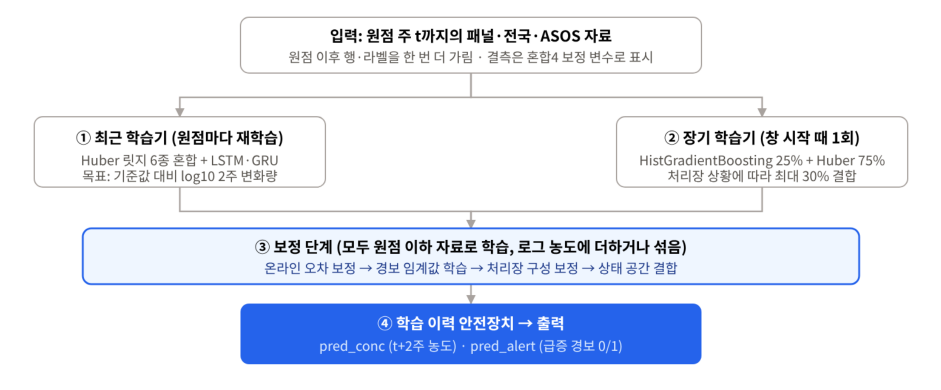

In [8]:
import matplotlib.image as mpimg
img = mpimg.imread(str(PKG / "figures" / "pipeline.png"))
plt.figure(figsize=(10, 4)); plt.imshow(img); plt.axis("off"); plt.tight_layout(); plt.show()

## 7. 재현성과 누수 방지 메모

- 난수 시드를 고정했고, 평가 창 사이에 상태나 디스크 캐시를 남기지 않습니다. 같은 환경에서 다시 실행하면 결과 파일이 바이트 단위로 같았습니다.
- 모델에는 KOWAS 관측값, 학습된 가중치, 평가 창·주차별 분기가 없습니다(README 9절).
- 학습 이력이 짧은 원점(26주 이하)에서는 기준 모델 쪽으로 물러나는 안전장치가 작동합니다.
- 외부 AI 서비스·API는 호출하지 않으며 네트워크를 쓰지 않습니다.